# Case study 1 · Question answering with retrieval (HotpotQA)

**The question:** in a retrieval-augmented (RAG) pipeline, what actually drives answer quality:
the retrieval, the model, or the combination of the two? And is each difference real, or just noise?

**The setup:** 50 hard multi-hop questions from HotpotQA, each needing facts from two Wikipedia
paragraphs. The pipeline has three stages, and every stage becomes a factor:

| Factor | Levels |
|---|---|
| `retrieval` | `none` · `dense` · `dense_with_reranker` |
| `model` | `gemma-3-4b` · `gpt-oss-20b` · `gpt-oss-120b` |
| `placebo` | `on` · `off` (both do nothing: a negative control) |

That gives 3 × 3 × 2 = **18 configurations × 50 questions = 900 answers**. An LLM judge from a
different model family scores each answer 0 (incorrect), 1 (partially correct) or 2 (correct).

**What this study shows in CAFE:** attribution (which factor explains how much), an interaction
(retrieval helps the small model most), a placebo correctly found to do nothing, the ordinal
mixed model for a 0/1/2 scale, the cost/quality Pareto front, and energy per configuration.

In [1]:
import json

import pandas as pd

import cafe

cafe.load_env();   # the API keys from the repo's .env

## 1 · The data

50 HotpotQA questions with their correct answers. `question_type` says whether a question links
two facts (`bridge`) or compares two things (`comparison`); it becomes a filter in the web app.

In [2]:
questions = json.load(open("data/hotpotqa_questions.json"))

dataset = [
    {"id": q["id"], "text": q["question"], "reference": q["answer"], "question_type": q["question_type"]}
    for q in questions
]

print(f"{len(dataset)} questions, for example:")
print("  question:", dataset[0]["text"])
print("  answer:  ", dataset[0]["reference"])

50 questions, for example:
  question: The first book in the Sprawl Trilogy won what three awards?
  answer:   Nebula Award, the Philip K. Dick Award, and the Hugo Award


## 2 · The system

The pipeline lives in [`pipeline.py`](pipeline.py) next to this notebook: the web app runs the
same file. Each stage has several interchangeable techniques.

In [3]:
from pipeline import pipe

for stage in pipe.stages():
    print(f"{stage:10s} → {', '.join(pipe.names_for(stage=stage))}")

retrieval  → none, dense, dense_with_reranker
model      → gemma-3-4b, gpt-oss-20b, gpt-oss-120b
placebo    → on, off


## 3 · The factors

Every stage becomes a factor whose levels are its techniques. CAFE runs every combination.

In [4]:
# The pipeline says which techniques exist; the factors say what this study varies.
# pipe.factor(stage=...) makes a factor whose levels are all the techniques of that stage, in the
# order of pipeline.py. names=[...] would pick a subset instead, for example
#     pipe.factor(stage="model", names=["gpt-oss-20b", "gpt-oss-120b"])
# Every stage with several techniques must be a factor (otherwise CAFE stops with an error);
# a stage with only one technique is simply used.
factors = [
    pipe.factor(stage="retrieval"),
    pipe.factor(stage="model"),
    pipe.factor(stage="placebo"),
]

## 4 · Rubric and judge

The judge compares each answer with the correct answer and scores it on a three-level scale.
Because the scale is ordered (0 < 1 < 2), CAFE analyses it with an ordinal mixed model.

In [5]:
answer_correctness = cafe.Rubric(
    name="answer_correctness",
    scale_type=cafe.ScaleType.ordinal,
    levels=[
        cafe.Level(value=0, label="incorrect", description="The answer is factually incorrect or off-topic."),
        cafe.Level(value=1, label="partially_correct", description="The answer is partially correct."),
        cafe.Level(value=2, label="correct", description="The answer is fully correct; wording does not matter."),
    ],
    instruction=(
        "Grade whether the ANSWER correctly answers the QUESTION, using the REFERENCE as the gold "
        "answer. Judge factual correctness, not phrasing or length; award partial credit for a "
        "partially-correct answer."
    ),
    prompt_template=(   # the exact judge prompt used in the paper
        "{instruction}\n\n"
        "[BEGIN DATA]\n***\nQuestion: {question}\n***\nReference (gold) answer: {reference}\n"
        "***\nAnswer to grade: {answer}\n***\n[END DATA]\n\n"
        "Reason briefly, then score on this scale:\n{scale}\n\n"
        "End with exactly one final line, and nothing after it:\nGRADE: <{grade}>"
    ),
)

# The judge: an LLM that scores each answer against the rubric (CAFE sends it a prompt it builds
# from the rubric, the question, the reference and the answer).
judge = cafe.LLMJudge(
    model="ollama_cloud/deepseek-v4-pro",   # a different model family from all three systems
    system_prompt=(
        "You will be shown a question, a reference (gold) answer, and an answer to grade. Follow the "
        "grading rules the user gives you, and be a fair, factual grader: judge only whether the "
        "answer is factually correct against the reference, not its style or length."
    ),
)

# The exact prompt the judge will see, for one example answer (no model is called here):
print(judge.preview(rubric=answer_correctness, question=dataset[0]["text"],
                    answer="The Hugo, Nebula and Philip K. Dick awards.",
                    reference=dataset[0]["reference"]))

[SYSTEM]
You will be shown a question, a reference (gold) answer, and an answer to grade. Follow the grading rules the user gives you, and be a fair, factual grader: judge only whether the answer is factually correct against the reference, not its style or length.

[USER]
Grade whether the ANSWER correctly answers the QUESTION, using the REFERENCE as the gold answer. Judge factual correctness, not phrasing or length; award partial credit for a partially-correct answer.

[BEGIN DATA]
***
Question: The first book in the Sprawl Trilogy won what three awards?
***
Reference (gold) answer: Nebula Award, the Philip K. Dick Award, and the Hugo Award
***
Answer to grade: The Hugo, Nebula and Philip K. Dick awards.
***
[END DATA]

Reason briefly, then score on this scale:
  0 = incorrect: The answer is factually incorrect or off-topic.
  1 = partially_correct: The answer is partially correct.
  2 = correct: The answer is fully correct; wording does not matter.

End with exactly one final line, a

## 5 · Run the study

First the plan and a quick preflight (one question through every configuration, with a time and
cost estimate), then the full run. The run saves its progress as it goes: if it is interrupted,
or some answers failed (e.g. a provider was briefly rate-limited), running the cell again
continues where it stopped and retries only the failed answers.

In [6]:
# A study = the system, the factors to vary, the inputs, and how to score the answers.
study = cafe.Study(
    name="question-answering-hotpotqa",
    system=pipe,
    factors=factors,
    dataset=dataset,
    rubric=answer_correctness,
    judge=judge,
)

print(study.plan())        # how many configurations, answers and judge calls (nothing runs yet)
print(study.preflight(concurrency=4))   # one input through every configuration: errors, time, cost

{'name': 'question-answering-hotpotqa', 'design': 'full_factorial', 'factors': ['retrieval', 'model', 'placebo'], 'configs': 18, 'items': 50, 'replications': 1, 'runs': 900, 'judged': True, 'judge_calls': 900}


Preflight(answers=Results(question-answering-hotpotqa: 18 answers, 18 configs, 0 errors), estimate={'sampled_cells': 18, 'total_cells': 900, 'est_total_compute_s': 34273.5, 'est_total_cost_usd': 0.0846, 'labels': ['model=gemma-3-4b·placebo=on·retrieval=none']}, warnings=[], judge_calls=900)


In [7]:
# Run every question through every configuration, judge every answer, then fit the statistics.
result = study.evaluate(
    concurrency=4,   # 4 at a time: Ollama Cloud rejects too many parallel requests
    checkpoint_path="results/answers.cafe.jsonl",
    judge_checkpoint_path="results/verdicts.cafe.jsonl",
)

question-answering-hotpotqa: answers: 100%  900/900 [35:22<00:00,  2.36s/it]


judging: 100%  900/900 [19:49<00:00,  1.32s/it]


## 6 · The results

The full report: means, attribution (which factor explains how much of the quality), effect
sizes, and the ordinal mixed model with one test per factor.

In [8]:
print(result.report())

900 answers · 18 configs · 50 inputs · 900 ratings · best: model=gpt-oss-20b·placebo=off·retrieval=dense_with_reranker

pipeline: 900 answers  →  900 judged  →  900 usable verdict(s)

────────────────────────────────────────────────────────────
DESCRIPTIVE — means & best configuration
────────────────────────────────────────────────────────────
verdicts: 900   factors: retrieval, model, placebo

overall mean quality: 1.35  (n=900)

per-configuration mean quality:
  1.80  (n=50)  model=gpt-oss-20b·placebo=off·retrieval=dense_with_reranker
  1.80  (n=50)  model=gpt-oss-20b·placebo=on·retrieval=dense_with_reranker
  1.78  (n=50)  model=gpt-oss-120b·placebo=off·retrieval=dense_with_reranker
  1.78  (n=50)  model=gpt-oss-120b·placebo=on·retrieval=dense_with_reranker
  1.70  (n=50)  model=gpt-oss-120b·placebo=off·retrieval=dense
  1.66  (n=50)  model=gpt-oss-120b·placebo=on·retrieval=dense
  1.64  (n=50)  model=gemma-3-4b·placebo=on·retrieval=dense_with_reranker
  1.60  (n=50)  model=gemma-3

The interaction: does retrieval help every model equally?

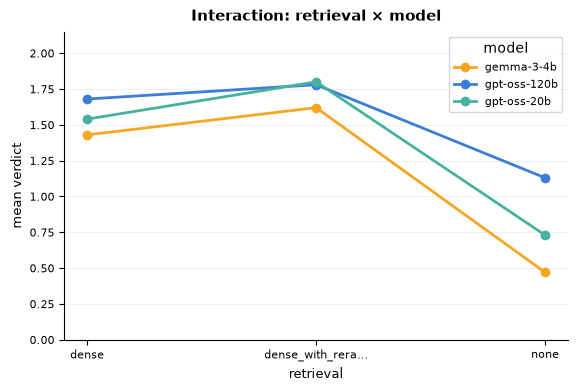

In [9]:
result.plot(kind="interaction", factors=["retrieval", "model"]);

Quality against cost: the configurations on the Pareto front are the only ones worth considering.

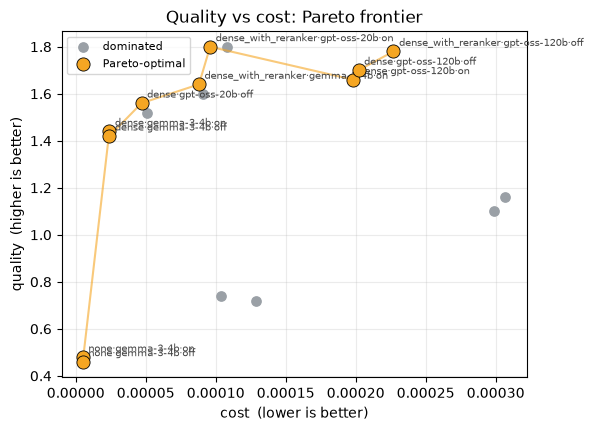

In [10]:
result.plot(kind="pareto");

Cost, energy and time per model, summed over all its answers:

In [11]:
answers = pd.DataFrame(result.records())
answers.groupby("model")[["cost_usd", "energy_wh", "elapsed_s"]].sum().round(4)

,cost_usd,energy_wh,elapsed_s
model,,,
gemma-3-4b,0.0118,16.9616,1711.2004
gpt-oss-120b,0.0731,38.9675,2795.5957
gpt-oss-20b,0.0268,29.3690,7116.1844


## 7 · Save for the web app

One file with everything: answers, verdicts, rubric and question metadata. In the web app,
**Studies → Import study** turns it into a browsable study.

In [12]:
cafe.save_evaluation(evaluation=result, path="results/question_answering_results.json")